# Un petit LLM ouvert, interrogé en zéro-shot sur un dossier de risque calculé par code, égale-t-il un GBDT appris sur ~1 000 clients étiquetés (défaut de crédit) ?

> **En bref.** Non concluant : le petit modèle de substitution ne lit pas le dossier et reste au niveau du hasard. L'expérience ne dit rien sur l'approche de la source, seulement que ce modèle est trop petit. AUC : 0,522 [0,441 ; 0,601] pour LLM zéro-shot (Qwen2.5-0.5B-Instruct), contre 0,667 [0,589 ; 0,746] pour XGBoost, 20000 étiquettes (192 exemples de test, échelle réduite, chiffres indicatifs).

| | |
|---|---|
| **Question** | L'AUC du score zéro-shot (P(« Yes ») d'un LLM ≤3B sur un dossier à indicateurs d'alerte précoce) dépasse celle du simple comptage d'indicateurs d'au moins 0,03 et atteint celle d'un XGBoost entraîné sur 300 à 1 000 clients ; XGBoost entraîné sur toutes les étiquettes reste devant d'au moins 0,05 d'AUC. |
| **Référence** | XGBoost supervisé à budget d'étiquettes variable — Classifieur à arbres boostés entraîné sur N demandes étiquetées (N = 100, 300, 1 000, 3 000, toutes) avec les variables brutes de la demande, plus une baseline sans apprentissage : le nombre d'indicateurs d'alerte précoce déclenchés. |
| **Nouvelle approche** | Score zéro-shot LLM sur dossier structuré (équivalent ouvert de JevRisk) — Le code calcule les indicateurs et monte un dossier JSON (profil, montants, indicateurs avec statut et chiffre). Un LLM ouvert répond à deux questions fermées (métier à haut risque ? client à haut risque ?) ; le score est le produit des probabilités de « Yes », lues sur les logits du premier token, sans génération. |
| **Données publiques** | [`mohameddhameem/home-credit-default-risk`](https://huggingface.co/datasets/mohameddhameem/home-credit-default-risk) (application_train_dated) |
| **Métrique principale** | AUC (à maximiser) |

**Sommaire** — 0. Mise en route · 1. La question · 2. Les données · 3. L'approche de référence · 4. La nouvelle approche · 5. Évaluation · 6. Analyse des résultats · 7. Bilan

**Trois façons d'exécuter ce notebook** (cellule de paramètres, section 0) :

| Réglage | À quoi ça sert |
|---|---|
| `PHASE = "public"`, `SCALE = "reduced"` | vérifier que tout fonctionne : quelques minutes sur CPU, sur un échantillon |
| `PHASE = "public"`, `SCALE = "full"` | reproduire les résultats publiés, sur tout le jeu public |
| `PHASE = "private"` | rejouer le même protocole sur vos données, dans votre environnement (voir le README) |

Les sorties affichées sont celles de l'échelle réduite (`SCALE = "reduced"`).

## 0. Mise en route

Trois réglages suffisent : la **phase** (quelles données), l'**échelle** (combien de données et quels modèles) et la **graine** (mêmes tirages, mêmes résultats). Le même code sert aux deux phases : seule la source des données change.

- `PHASE = "public"` charge le jeu public ; `PHASE = "private"` lit vos données d'après `PRIVATE_CONFIG` (cellule suivante) et appelle vos services internes. En phase `private`, aucune donnée brute n'est affichée.
- `SCALE = "reduced"` prend un petit échantillon et, si besoin, des modèles plus petits de la même famille : c'est un test de la mécanique, ses chiffres ne valent pas résultat. `SCALE = "full"` utilise tout le jeu.
- Les fonctions communes (chargement des données internes, appels de services, intervalles de confiance, figures, enregistrement des résultats) sont dans `helpers.py`, à côté du notebook.

Fonctions de `helpers.py` utilisées ici :

| Fonction | Rôle |
|---|---|
| `set_seed` | Graine unique pour random, numpy et torch (s'ils sont présents) : résultats reproductibles. |
| `device` | Matériel de calcul disponible : « cuda » (GPU NVIDIA), « mps » (GPU Apple) ou « cpu ». |
| `sample_size` | Nombre d'exemples à utiliser : `reduced` à l'échelle réduite, `full` (None = tout le jeu) à l'échelle complète. |
| `by_scale` | Valeur qui dépend de l'échelle : modèle substitut, nombre d'époques, de pas ou d'exemples. |
| `openai_client` | Client `openai` vers le service <PREFIX>. Proxy et certificats d'entreprise : HTTPS_PROXY, SSL_CERT_FILE ; en-têtes exigés par une passerelle : <PREFIX>_HEADERS (objet JSON). |
| `model_path` | Chemin à passer à `from_pretrained`, dans les deux phases : l'identifiant Hugging Face, ou son dossier local sous LOCAL_MODELS_DIR (org--nom ou org/nom), seul accessible dans un environnement sans Internet. |
| `llm_chat` | Appel chat/completions. Avec `schema` (JSON Schema), rend l'objet décodé (None si la sortie est illisible) : sortie structurée si le service la prend en charge (mode strict si le schéma s'y prête), sinon consigne dans le prompt et décodage tolérant. |
| `resample` | Rééchantillonnage (scipy s'il est présent, sinon interpolation linéaire). |
| `load_private_data` | Jeu de la phase « private » : DataFrame aux colonnes attendues, lu dans PRIVATE_CONFIG['data'] (ou PRIVATE_DATA), fichier ou dossier (csv, tsv, parquet, jsonl, json, xlsx). |
| `preview` | Premières lignes en phase « public » ; en phase « private », seulement la structure (sauf SHOW_EXAMPLES=1). |
| `timer` | Mesure une durée en millisecondes : `with timer(liste): ...` ajoute la durée à `liste`. |
| `latency_stats` | Médiane (p50) et 95e centile (p95) d'une liste de durées en millisecondes. |
| `bootstrap_ci` | Valeur de `metric(y_true, y_pred)` et son intervalle de confiance à 95 % par bootstrap : (valeur, bas, haut). |
| `save_results` | Valide puis écrit results_<phase>.json dans le dossier des résultats. Structure attendue : |
| `results_table` | Tableau comparatif : une ligne par approche, chaque métrique avec son intervalle de confiance. |
| `save_figure` | Enregistre la figure (figures/<name>.png), l'affiche avec sa légende et la ferme ; ne renvoie rien. |
| `plot_comparison` | Figure de synthèse : une barre par approche et par métrique, avec l'intervalle de confiance à 95 % quand il existe. Par défaut, la métrique principale puis jusqu'à trois autres métriques. Une métrique sans objet pour une approche (None) n'a pas de barre pour elle. |

In [1]:
PHASE = "public"        # "public" : jeu public ; "private" : vos données, dans votre environnement
SCALE = "reduced"       # "reduced" : échantillon, quelques minutes sur CPU ; "full" : tout le jeu
SEED = 42               # graine : mêmes tirages, mêmes résultats
OUTPUT_DIR = "outputs"  # résultats (results_<phase>.json) et figures

### Configuration pour vos données

À modifier seulement pour `PHASE = "private"`. Chaque entrée est expliquée en commentaire ; les valeurs par défaut viennent des variables d'environnement décrites dans `private.env.example`. Au lancement, une liste de contrôle vérifie le jeu, les colonnes, les modèles et les services, et s'arrête sur ce qui manque avant tout calcul.

In [3]:
# Configuration pour vos données (PHASE = "private") : seule cellule à adapter.
# Les valeurs par défaut viennent de l'environnement (modèle : private.env.example).
# Aucune clé ici : elle vient de <SERVICE>_API_KEY, d'un fichier de secret monté (<SERVICE>_API_KEY_FILE) ou d'une saisie masquée.
import os

PRIVATE_CONFIG = {
    # Jeu de données : un fichier (csv, tsv, parquet, jsonl, json, xlsx) ou un dossier de fichiers de même structure.
    "data": os.environ.get("PRIVATE_DATA", ""),
    # Colonne attendue par le notebook -> nom de la colonne dans votre jeu (ne modifier que la partie droite).
    "columns": {'customer_id': 'customer_id', 'application_date': 'application_date', 'occupation': 'occupation', 'age': 'age', 'income': 'income', 'credit_amount': 'credit_amount', 'annuity': 'annuity', 'employment_years': 'employment_years', 'target': 'target'},
    # Colonnes qui contiennent des chemins de fichiers (relatifs au fichier de données qui les cite, ou absolus).
    "path_columns": [],
    "max_rows": None,                         # plafond facultatif (échantillon aléatoire reproductible)
    "csv": {"sep": None, "encoding": None},   # None : séparateur et encodage devinés (« ; », Windows-1252…)
    # Poids des modèles copiés localement (dossiers org--nom/, script download_models.py), pour travailler sans Internet.
    "models_dir": os.environ.get("LOCAL_MODELS_DIR", ""),
    "models": {'reduced': ['Qwen/Qwen2.5-0.5B-Instruct'], 'full': ['Qwen/Qwen2.5-1.5B-Instruct', 'Qwen/Qwen2.5-3B-Instruct']},
    # Autorité de certification d'entreprise (fichier PEM) pour les appels HTTPS internes ; vide sinon.
    "ca_bundle": os.environ.get("SSL_CERT_FILE", ""),
    "llmaas": {"base_url": os.environ.get("LLMAAS_BASE_URL", ""), "model": os.environ.get("LLMAAS_MODEL", ""),
               "api_key_file": os.environ.get("LLMAAS_API_KEY_FILE", ""),
               "headers": {}},  # en-têtes exigés par votre passerelle, s'il y en a
}

### Dépendances et initialisation

Les versions exactes utilisées pour les résultats publiés sont dans `requirements.txt`. Les paquets propres à cette expérience s'installent depuis le notebook avec `INSTALL_DEPENDENCIES=1`.

In [4]:
# Paquets propres à cette expérience (en plus de requirements.txt).
EXTRA_PACKAGES = []
import os, subprocess, sys
if EXTRA_PACKAGES and os.environ.get("INSTALL_DEPENDENCIES") == "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *EXTRA_PACKAGES])

In [5]:
from helpers import *  # fonctions communes (voir le tableau ci-dessus)

configure(phase=PHASE, scale=SCALE, seed=SEED, output_dir=OUTPUT_DIR)
apply_private_config(PRIVATE_CONFIG)  # phase private : liste de contrôle, arrêt si quelque chose manque
prepare_environment()                 # télémétrie coupée ; hors ligne si les modèles sont locaux
use_plot_style()
show_configuration()

PHASE=public  SCALE=reduced  SEED=42  device=cpu  python=3.12.16
service LLM (convention OpenAI)               LLMAAS_BASE_URL=—  LLMAAS_MODEL=—  clé absente
service de transcription (convention OpenAI)  STTAAS_BASE_URL=—  STTAAS_MODEL=—  clé absente
données internes : —  modèles locaux : —


## 1. La question

Pour noter le risque de défaut d'un demandeur de crédit, on entraîne d'habitude un modèle **supervisé**. Il apprend sur des clients dont on connaît déjà l'issue, et chaque étiquette coûte des mois d'historique. Une publication récente (JevRisk) affirme qu'un modèle de langage interrogé **sans aucun exemple étiqueté** (*zéro-shot*) atteint le niveau d'un modèle supervisé appris sur environ 1 000 clients.

Cette expérience vérifie l'idée avec un **petit LLM ouvert** (≤ 3 Md de paramètres) exécuté localement, sur des demandes de crédit réelles et publiques.

### L'idée, en une analogie

Le code joue le rôle du **comptable** : il calcule les chiffres exacts et les signaux d'alerte. Le LLM joue celui de l'**analyste** qui lit le dossier et répond par oui ou non. On ne lui demande pas de rédiger : on lit directement la probabilité qu'il réponde « Yes ».

1. Le code calcule des **indicateurs d'alerte précoce** (mensualité/revenu, crédit/revenu, ancienneté d'emploi…). Les seuils viennent de règles fixes ou de percentiles de la période passée.
2. Le code monte un **dossier JSON** : profil, montants, indicateurs avec leur statut et le chiffre qui le justifie.
3. Le LLM répond à deux questions fermées : « le métier est-il à haut risque ? » et « ce client est-il à haut risque ? ».
4. **Score = P(Yes métier) × P(Yes client)**, qui sert à classer les clients.

### Ce que la comparaison permet de décider

- Le LLM fait-il mieux que le **simple comptage d'indicateurs**, d'au moins 0,03 d'AUC ?
- À partir de **combien d'étiquettes** un XGBoost le dépasse-t-il nettement ?
- Avec toutes les étiquettes, l'avance du supervisé dépasse-t-elle 0,05 d'AUC ?

Si l'intervalle de confiance du LLM contient 0,5 (le hasard), la conclusion est « non concluant », et elle sera publiée telle quelle.

## 2. Les données

### Outils communs

On importe les bibliothèques utilisées dans tout le notebook. `rankdata` sert à calculer une AUC rapide par les rangs, ce qui rend le bootstrap bon marché.

In [6]:
import gc
import json
import math
import os
import time
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from scipy.stats import rankdata

pd.set_option("display.max_columns", 30)
os.environ["TQDM_DISABLE"] = "1"  # barres de progression désactivées
set_seed(SEED)

### Réglages des données

- Le jeu public n'a qu'un split « train ». On fait nous-mêmes un **découpage temporel** : les demandes les plus récentes servent au test, les plus anciennes au développement.
- Le test est **équilibré** (autant de défauts que de non-défauts). L'AUC ne dépend pas de cette proportion, et le rappel sera repondéré au taux réel.

In [7]:
DATASET_ID = "mohameddhameem/home-credit-default-risk"  # demandes de crédit publiques avec défaut observé
DATASET_CONFIG = "application_train_dated"  # variante qui contient la date de demande
DATASET_SPLIT = "train"  # seul split publié ; le découpage temporel est fait ici
TEST_FRACTION = 0.2  # part la plus récente des demandes réservée au test
N_DEV = sample_size(reduced=20000, full=100000)  # demandes de développement conservées
N_TEST_PER_CLASS = sample_size(reduced=100, full=1000)  # clients de test par classe
MIN_TEST = 100  # en deçà, l'évaluation n'est pas concluante
N_FAKE = 3000  # lignes du jeu factice (phase private)

# Colonnes du jeu public : le genre sert seulement au contrôle d'équité, EXT_SOURCE_* sont exclus
PUBLIC_COLUMNS = ["SK_ID_CURR", "application_date", "TARGET", "NAME_CONTRACT_TYPE", "AMT_INCOME_TOTAL",
                  "AMT_CREDIT", "AMT_ANNUITY", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE",
                  "OCCUPATION_TYPE", "DAYS_BIRTH", "DAYS_EMPLOYED", "CODE_GENDER"]
# Schéma commun aux deux phases (celui des données internes)
COMMON_COLUMNS = ["customer_id", "application_date", "occupation", "age", "income",
                  "credit_amount", "annuity", "employment_years", "target"]
NUMERIC_COLUMNS = ["age", "income", "credit_amount", "annuity", "employment_years"]
EXTRA_CATEGORICAL: list[str] = []  # variables catégorielles en plus (jeu public seulement)

### Un nettoyage identique pour les deux phases

`to_common_frame` convertit **explicitement** les types (dates, nombres, textes). La classe positive est déduite des données : c'est la plus grande des deux valeurs de la cible. Les lignes sans date, sans cible ou sans montant sont retirées.

In [8]:
def to_common_frame(frame: pd.DataFrame, extra_categorical: list[str],
                    audit_columns: list[str]) -> pd.DataFrame:
    """Convertit les types et nettoie un jeu au schéma commun.

    `audit_columns` (ex. le genre) sont gardées pour l'audit, jamais données aux modèles.
    """
    out = frame[COMMON_COLUMNS + extra_categorical + audit_columns].copy()
    out["customer_id"] = out["customer_id"].astype(str)
    out["application_date"] = pd.to_datetime(out["application_date"], errors="coerce")
    for column in NUMERIC_COLUMNS:
        out[column] = pd.to_numeric(out[column], errors="coerce")
    for column in ["occupation"] + extra_categorical + audit_columns:
        out[column] = out[column].fillna("Not reported").astype(str).str.strip()
        out.loc[out[column].isin(["", "nan", "None"]), column] = "Not reported"
    target = pd.to_numeric(out["target"], errors="coerce")
    values = sorted(target.dropna().unique())
    assert len(values) == 2, f"Cible binaire attendue, valeurs trouvées : {values}"
    out["target"] = (target == values[1]).astype(float).where(target.notna())
    out = out.dropna(subset=["application_date", "target", "income", "credit_amount"])
    out = out[out["income"] > 0].copy()
    out["target"] = out["target"].astype(int)
    return out.reset_index(drop=True)

### Découpage temporel et test équilibré

- `temporal_split` trie par date (puis par identifiant, pour départager les ex aequo) et coupe : le développement est **strictement antérieur** au test dans l'ordre chronologique.
- `balanced_test_sample` tire autant de clients par classe, puis **mélange l'ordre**. Si le budget de temps coupe l'inférence, les clients déjà notés restent ainsi un échantillon aléatoire.

In [9]:
def temporal_split(frame: pd.DataFrame, test_fraction: float) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Coupe le jeu trié par date : (développement ancien, réserve de test récente)."""
    ordered = frame.sort_values(["application_date", "customer_id"], kind="mergesort")
    cut = int(len(ordered) * (1 - test_fraction))
    return ordered.iloc[:cut].reset_index(drop=True), ordered.iloc[cut:].reset_index(drop=True)


def balanced_test_sample(pool: pd.DataFrame, n_per_class: int, seed: int) -> pd.DataFrame:
    """Tire n clients par classe (dans la limite du disponible), puis mélange l'ordre."""
    n = int(min(n_per_class, pool["target"].value_counts().min()))
    sample = pool.groupby("target", group_keys=False).sample(n=n, random_state=seed)
    return sample.sample(frac=1.0, random_state=seed).reset_index(drop=True)


def split_summary(dev_all: pd.DataFrame, dev: pd.DataFrame, test: pd.DataFrame) -> pd.DataFrame:
    """Effectifs, taux de défaut et période de chaque partie."""
    rows = []
    for name, part in [("Développement (tout)", dev_all), ("Développement (échantillon)", dev),
                       ("Test équilibré", test)]:
        rows.append({"partie": name, "demandes": len(part), "défauts": int(part["target"].sum()),
                     "taux de défaut (%)": round(100 * part["target"].mean(), 2),
                     "début": part["application_date"].min().date(),
                     "fin": part["application_date"].max().date()})
    return pd.DataFrame(rows)

### Figure des données

À gauche, le nombre de demandes et le taux de défaut par mois, avec la frontière développement/test. À droite, les effectifs par classe de chaque partie. Une date trop régulière ou un taux de défaut qui saute à la frontière signalerait une date reconstituée ou une dérive.

In [10]:
def plot_data_overview(frame: pd.DataFrame, dev_all: pd.DataFrame, dev: pd.DataFrame,
                       test: pd.DataFrame) -> None:
    """Volume et taux de défaut mensuels, frontière temporelle, effectifs par classe."""
    monthly = frame.set_index("application_date").resample("MS")["target"].agg(["size", "mean"])
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    axes[0].plot(monthly.index, monthly["size"], color=COLORS["reference"], label="demandes")
    axes[0].set_xlabel("mois de la demande")
    axes[0].set_ylabel("demandes par mois")
    twin = axes[0].twinx()
    twin.plot(monthly.index, 100 * monthly["mean"], color=COLORS["bad"], label="taux de défaut")
    twin.set_ylabel("taux de défaut (%)")
    axes[0].axvline(dev_all["application_date"].max(), color=COLORS["accent"], linestyle="--",
                    label="frontière dév./test")
    axes[0].legend(loc="upper left")
    axes[0].set_title("Demandes et défauts dans le temps")
    counts = pd.DataFrame({"Développement": dev["target"].value_counts(),
                           "Test": test["target"].value_counts()}).T
    counts = counts.rename(columns={0: "sans défaut (0)", 1: "défaut (1)"})
    counts.plot.bar(ax=axes[1], color=[COLORS["good"], COLORS["bad"]], rot=0)
    axes[1].set_ylabel("nombre de demandes")
    axes[1].set_title("Effectifs par classe")
    save_figure(fig, "data_overview", "Gauche : demandes par mois et taux de défaut (%), frontière "
                "temporelle en pointillés. Droite : effectifs par classe (développement échantillonné, "
                "test équilibré).")

### Chargement du jeu public

On lit le parquet du Hub, puis on garde les seules colonnes utiles. On les traduit dans le schéma commun :

- âge = −`DAYS_BIRTH`/365,25 ;
- ancienneté = −`DAYS_EMPLOYED`/365,25. La valeur sentinelle 365 243 (retraités, sans emploi) devient « non renseignée ».

Les scores externes `EXT_SOURCE_*` sont exclus, comme dans la source. Le genre n'est gardé que pour l'audit.

In [11]:
if PHASE == "public":
    from datasets import load_dataset
    raw_dataset = load_dataset(DATASET_ID, DATASET_CONFIG, split=DATASET_SPLIT)
    raw = raw_dataset.select_columns(PUBLIC_COLUMNS).to_pandas()
    days_employed = pd.to_numeric(raw["DAYS_EMPLOYED"], errors="coerce")
    mapped = pd.DataFrame({
        "customer_id": raw["SK_ID_CURR"],
        "application_date": raw["application_date"],
        "occupation": raw["OCCUPATION_TYPE"],
        "age": np.floor(-pd.to_numeric(raw["DAYS_BIRTH"], errors="coerce") / 365.25),
        "income": raw["AMT_INCOME_TOTAL"],
        "credit_amount": raw["AMT_CREDIT"],
        "annuity": raw["AMT_ANNUITY"],
        "employment_years": (-days_employed.where(days_employed <= 0)) / 365.25,
        "target": raw["TARGET"],
        "contract_type": raw["NAME_CONTRACT_TYPE"],
        "income_type": raw["NAME_INCOME_TYPE"],
        "education": raw["NAME_EDUCATION_TYPE"],
        "gender": raw["CODE_GENDER"],
    })
    EXTRA_CATEGORICAL = ["contract_type", "income_type", "education"]
    full_frame = to_common_frame(mapped, EXTRA_CATEGORICAL, audit_columns=["gender"])
    dev_all, test_pool = temporal_split(full_frame, TEST_FRACTION)
    dev = dev_all.sample(n=min(N_DEV, len(dev_all)), random_state=SEED).reset_index(drop=True)
    test = balanced_test_sample(test_pool, N_TEST_PER_CLASS, SEED)
    dataset_info = {"name": DATASET_ID, "config": DATASET_CONFIG, "split": f"{DATASET_SPLIT} (découpage temporel)"}
    del raw, mapped, raw_dataset
    print(f"{len(full_frame):,} demandes après nettoyage ; dates distinctes : "
          f"{full_frame['application_date'].nunique():,}")

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Generating train split:   0%|          | 0/307511 [00:00<?, ? examples/s]

Generating train split:   4%|▍         | 12000/307511 [00:00<00:03, 87747.40 examples/s]

Generating train split:  11%|█         | 33000/307511 [00:00<00:01, 147134.34 examples/s]

Generating train split:  17%|█▋        | 53000/307511 [00:00<00:01, 167074.48 examples/s]

Generating train split:  24%|██▍       | 74000/307511 [00:00<00:01, 179987.76 examples/s]

... (7 outputs left out)

Generating train split:  90%|█████████ | 278000/307511 [00:01<00:00, 260375.57 examples/s]

Generating train split: 100%|█████████▉| 307000/307511 [00:01<00:00, 265700.48 examples/s]

Generating train split: 100%|██████████| 307511/307511 [00:01<00:00, 219343.16 examples/s]

307,511 demandes après nettoyage ; dates distinctes : 1,096


### Contrôles, figure et exemples

On vérifie les effectifs, les taux de défaut et les périodes. On regarde aussi si la frontière tombe au milieu d'une même date : le développement serait alors seulement « antérieur dans l'ordre », pas strictement antérieur dans le calendrier.

,partie,demandes,défauts,taux de défaut (%),début,fin
0,Développement (tout),246008,19941,8.11,2018-01-01,2020-05-25
1,Développement (échantillon),20000,1574,7.87,2018-01-01,2020-05-25
2,Test équilibré,200,100,50.00,2020-05-27,2020-12-29


Frontière au milieu d'une même date : non


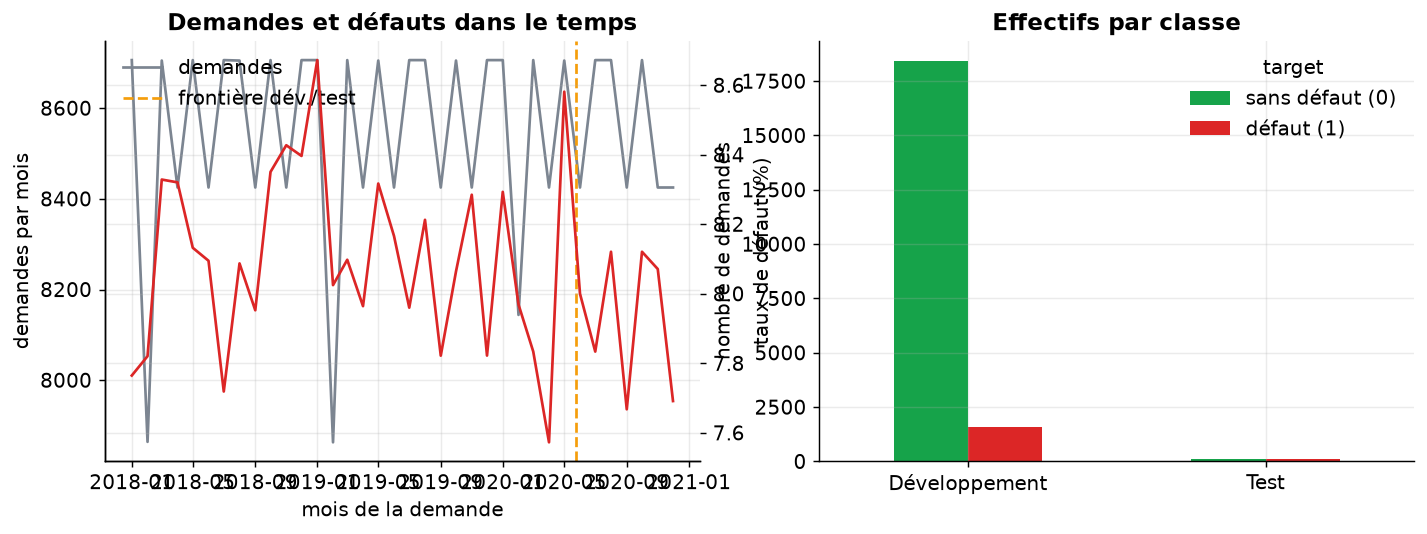

*Figure — Gauche : demandes par mois et taux de défaut (%), frontière temporelle en pointillés. Droite : effectifs par classe (développement échantillonné, test équilibré).*

In [12]:
if PHASE == "public":
    display(split_summary(dev_all, dev, test))
    shared_day = dev_all["application_date"].max() == test_pool["application_date"].min()
    print("Frontière au milieu d'une même date :", "oui" if shared_day else "non")
    assert len(test) >= MIN_TEST, "Test trop petit pour conclure"
    plot_data_overview(full_frame, dev_all, dev, test)
    preview(test[COMMON_COLUMNS + EXTRA_CATEGORICAL])

### Jeu factice au format des données internes

`make_fake_data` fabrique des demandes **entièrement inventées**, aux colonnes attendues : dates sur deux ans, métiers génériques, revenus log-normaux. Le risque est simulé par une loi logistique sur des facteurs plausibles. Il sert seulement à vérifier que tout le code tourne : ses chiffres ne veulent rien dire.

In [13]:
PRIVATE_COLUMNS = {
    "customer_id": "Identifiant pseudonymisé du client ou du dossier.",
    "application_date": "Date de la demande ou de la revue, pour le découpage temporel.",
    "occupation": "Profession ou code métier (sans identité).",
    "age": "Âge à la date de la demande.",
    "income": "Revenu déclaré annuel.",
    "credit_amount": "Montant demandé ou encours.",
    "annuity": "Mensualité ou échéance.",
    "employment_years": "Ancienneté d'emploi ou de relation.",
    "target": "1 si défaut ou risque confirmé dans la fenêtre d'observation, sinon 0.",
}


def make_fake_data(n: int) -> pd.DataFrame:
    """Demandes fictives plausibles (aucune donnée réelle), environ 30 % de risque."""
    rng = np.random.default_rng(SEED)
    occupations = np.array(["Laborers", "Sales staff", "Core staff", "Managers", "Drivers",
                            "Accountants", "Cooking staff", "Security staff", "Cleaning staff",
                            "Medicine staff", "IT staff", "Not reported"])
    age = rng.integers(19, 70, n)
    income = np.round(rng.lognormal(10.3, 0.5, n), -2)
    credit = np.round(income * rng.lognormal(1.0, 0.6, n), -2)
    annuity = np.round(credit * rng.uniform(0.04, 0.14, n), 2)
    employment = np.round(np.minimum(rng.exponential(6.0, n), age - 18), 1)
    dates = pd.Timestamp("2023-01-01") + pd.to_timedelta(rng.integers(0, 730, n), unit="D")
    logit = (-1.3 + 0.9 * (annuity / income > 0.35) + 0.6 * (credit / income > 5)
             + 0.7 * (employment < 1) + 0.5 * (age < 25) - 0.4 * np.log(income / 30000)
             + rng.normal(0, 0.8, n))
    target = (rng.random(n) < 1 / (1 + np.exp(-logit))).astype(int)
    return pd.DataFrame({
        "customer_id": [f"C{i:06d}" for i in range(n)],
        "application_date": dates.strftime("%Y-%m-%d"),
        "occupation": rng.choice(occupations, n), "age": age, "income": income,
        "credit_amount": credit, "annuity": annuity, "employment_years": employment,
        "target": target})

### Chargement et mêmes transformations

`load_private_data` relit le jeu interne, ou le jeu factice, depuis un fichier. On applique **exactement** le même nettoyage, le même découpage temporel et le même tirage qu'en phase publique. Seuls des effectifs et des agrégats sont affichés.

In [14]:
if PHASE == "private":
    private_raw = load_private_data(PRIVATE_COLUMNS, make_fake_data, n_fake=N_FAKE)
    EXTRA_CATEGORICAL = []  # le schéma interne ne contient que les colonnes communes
    full_frame = to_common_frame(private_raw, EXTRA_CATEGORICAL, audit_columns=[])
    dev_all, test_pool = temporal_split(full_frame, TEST_FRACTION)
    dev = dev_all.sample(n=min(N_DEV, len(dev_all)), random_state=SEED).reset_index(drop=True)
    test = balanced_test_sample(test_pool, N_TEST_PER_CLASS, SEED)
    dataset_info = {"name": "données internes", "config": "private", "split": "découpage temporel"}
    display(split_summary(dev_all, dev, test))
    assert len(test) >= MIN_TEST, "Test trop petit pour conclure"
    plot_data_overview(full_frame, dev_all, dev, test)
    preview(test[COMMON_COLUMNS])

POPULATION_RATE = float(dev["target"].mean())  # taux de défaut réel, pour repondérer le rappel
y_test = test["target"].to_numpy()
print(f"Développement : {len(dev):,} | test : {len(test):,} | taux de défaut au développement : "
      f"{100 * POPULATION_RATE:.2f} %")

Développement : 20,000 | test : 200 | taux de défaut au développement : 7.87 %


## 3. L'approche de référence

### Indicateurs d'alerte précoce

Six signaux simples, inspirés des signaux d'alerte précoce des lignes directrices européennes :

- mensualité/revenu > 0,35 ; crédit/revenu > 5 ;
- ancienneté d'emploi < 1 an ; âge < 25 ans ;
- crédit au-dessus du **95e percentile** ; revenu sous le **25e percentile**.

Les deux percentiles sont calculés **sur le développement seulement**, jamais sur le test. Une valeur manquante compte comme « absent ».

In [15]:
DEBT_SERVICE_LIMIT = 0.35  # mensualité / revenu au-delà de laquelle l'alerte se déclenche
LEVERAGE_LIMIT = 5.0  # crédit / revenu au-delà duquel l'alerte se déclenche
SHORT_EMPLOYMENT_YEARS = 1.0  # ancienneté d'emploi jugée courte (années)
YOUNG_AGE_YEARS = 25  # âge sous lequel l'alerte se déclenche
THRESHOLDS = {"large_credit": float(dev["credit_amount"].quantile(0.95)),  # 95e percentile du dév.
              "low_income": float(dev["income"].quantile(0.25))}  # 25e percentile du dév.

# nom -> (définition donnée au LLM, colonne qui porte le chiffre justificatif)
INDICATOR_DEFINITIONS = {
    "high_debt_service": (f"Annuity above {DEBT_SERVICE_LIMIT:.0%} of annual income", "annuity_to_income"),
    "high_leverage": (f"Credit above {LEVERAGE_LIMIT:g} times annual income", "credit_to_income"),
    "short_employment": (f"Employed for less than {SHORT_EMPLOYMENT_YEARS:g} year", "employment_years"),
    "young_applicant": (f"Applicant younger than {YOUNG_AGE_YEARS}", "age"),
    "large_credit": (f"Credit above {THRESHOLDS['large_credit']:,.0f} (95th percentile of past applications)", "credit_amount"),
    "low_income": (f"Income below {THRESHOLDS['low_income']:,.0f} (25th percentile of past applications)", "income"),
}


def compute_indicators(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Renvoie (statuts booléens des indicateurs, ratios utiles au dossier)."""
    ratios = pd.DataFrame({"annuity_to_income": frame["annuity"] / frame["income"],
                           "credit_to_income": frame["credit_amount"] / frame["income"]})
    flags = pd.DataFrame({  # une comparaison avec NaN donne False : manquant = absent
        "high_debt_service": ratios["annuity_to_income"] > DEBT_SERVICE_LIMIT,
        "high_leverage": ratios["credit_to_income"] > LEVERAGE_LIMIT,
        "short_employment": frame["employment_years"] < SHORT_EMPLOYMENT_YEARS,
        "young_applicant": frame["age"] < YOUNG_AGE_YEARS,
        "large_credit": frame["credit_amount"] > THRESHOLDS["large_credit"],
        "low_income": frame["income"] < THRESHOLDS["low_income"]})
    return flags.astype(bool), ratios

### Baseline sans apprentissage : le comptage d'indicateurs

Le score est le **nombre d'indicateurs déclenchés** (0 à 6), comme les systèmes à seuils fixes. On définit aussi `fast_auc`, une AUC calculée par les rangs :

$AUC = \frac{\sum_{i \in +} r_i - n_+(n_+ + 1)/2}{n_+ \, n_-}$

C'est la probabilité qu'un client en défaut soit classé au-dessus d'un client sain. Les ex aequo comptent pour moitié.

In [16]:
def fast_auc(labels: np.ndarray, scores: np.ndarray) -> float:
    """AUC par les rangs (ex aequo comptés pour moitié) ; NaN si une seule classe."""
    labels = np.asarray(labels).astype(int)
    n_pos = int(labels.sum())
    n_neg = len(labels) - n_pos
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    ranks = rankdata(np.asarray(scores, dtype=float))
    return float((ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


test_flags, test_ratios = compute_indicators(test)
count_latency: list[float] = []
with timer(count_latency):
    count_scores = compute_indicators(test)[0].sum(axis=1).to_numpy(dtype=float)

approach_runs: list[dict] = [{  # registre commun de toutes les approches
    "name": "Comptage d'indicateurs", "role": "reference", "scores": count_scores[:, None],
    "n_labels": 0, "tokens_per_client": None, "latency": [count_latency[0] / len(test)],
    "notes": "Nombre d'indicateurs d'alerte précoce déclenchés (0 à 6), sans apprentissage."}]

prevalence = pd.DataFrame({"taux sur le test (%)": 100 * test_flags.mean(),
                           "taux de défaut si présent (%)": [100 * y_test[test_flags[c]].mean()
                                                            if test_flags[c].any() else np.nan
                                                            for c in test_flags]}).round(1)
display(prevalence)
print(f"AUC du comptage sur tout le test : {fast_auc(y_test, count_scores):.3f}")

,taux sur le test (%),taux de défaut si présent (%)
high_debt_service,5.0,50.0
high_leverage,34.5,49.3
short_employment,10.0,70.0
young_applicant,3.0,66.7
large_credit,6.0,25.0
low_income,24.5,55.1


AUC du comptage sur tout le test : 0.527


### Variables du modèle supervisé

XGBoost reçoit les **variables brutes** de la demande : âge, revenu, montants, ancienneté et métier, plus le type de contrat, de revenu et l'éducation en phase publique. Les catégories sont **encodées ordinalement** d'après le développement. Une catégorie inconnue devient une valeur manquante, que XGBoost sait traiter. Le genre n'entre jamais dans le modèle.

In [17]:
CATEGORICAL_COLUMNS = ["occupation"] + EXTRA_CATEGORICAL
FEATURE_COLUMNS = NUMERIC_COLUMNS + CATEGORICAL_COLUMNS


def encode_features(frame: pd.DataFrame, categories: dict[str, list[str]]) -> pd.DataFrame:
    """Matrice numérique : catégories -> code ordinal (inconnue -> NaN)."""
    features = frame[FEATURE_COLUMNS].copy()
    for column in CATEGORICAL_COLUMNS:
        codes = pd.Categorical(features[column], categories=categories[column]).codes.astype(float)
        features[column] = np.where(codes < 0, np.nan, codes)
    return features.astype(float)


categories = {column: sorted(dev[column].unique()) for column in CATEGORICAL_COLUMNS}
X_dev, y_dev = encode_features(dev, categories), dev["target"].to_numpy()
X_test = encode_features(test, categories)
print(f"Variables : {FEATURE_COLUMNS}")

Variables : ['age', 'income', 'credit_amount', 'annuity', 'employment_years', 'occupation', 'contract_type', 'income_type', 'education']


### XGBoost à budget d'étiquettes variable

Pour chaque budget N (100, 300, 1 000, 3 000, tout), on tire N demandes étiquetées dans le développement. Le tirage est **stratifié**, pour garder le taux de défaut. On entraîne ensuite un XGBoost (300 arbres, profondeur 4, pas 0,05). Chaque budget est répété sur plusieurs tirages : avec 100 étiquettes, le résultat dépend beaucoup de l'échantillon. Un budget plus grand que le développement est ignoré.

In [18]:
from xgboost import XGBClassifier

XGB_PARAMS = {"n_estimators": 300, "max_depth": 4, "learning_rate": 0.05,  # réglage du plan
              "tree_method": "hist", "n_jobs": os.cpu_count() or 2}
LABEL_BUDGETS = by_scale(reduced=[100, 300, 1000, "all"], full=[100, 300, 1000, 3000, "all"])
N_DRAWS = by_scale(reduced=1, full=10)  # tirages par budget (hors « all »)


def draw_labelled_subset(labels: np.ndarray, n: int, seed: int) -> np.ndarray:
    """Indices de n demandes tirées en gardant la proportion de défauts (au moins 2 par classe)."""
    rng = np.random.default_rng(seed)
    positives, negatives = np.flatnonzero(labels == 1), np.flatnonzero(labels == 0)
    n_pos = min(max(2, int(round(n * len(positives) / len(labels)))), len(positives))
    return np.concatenate([rng.choice(positives, n_pos, replace=False),
                           rng.choice(negatives, n - n_pos, replace=False)])


for budget in LABEL_BUDGETS:
    if budget != "all" and budget >= len(dev):
        print(f"Budget {budget} ignoré : le développement n'a que {len(dev)} demandes.")
        continue
    draws = 1 if budget == "all" else N_DRAWS
    scores, latency = np.zeros((len(test), draws)), []
    for draw in range(draws):
        index = np.arange(len(dev)) if budget == "all" else draw_labelled_subset(y_dev, budget, SEED + draw)
        model = XGBClassifier(**XGB_PARAMS, random_state=SEED + draw)
        model.fit(X_dev.iloc[index], y_dev[index])
        durations: list[float] = []
        with timer(durations):
            scores[:, draw] = model.predict_proba(X_test)[:, 1]
        latency.append(durations[0] / len(test))
    n_labels = len(dev) if budget == "all" else budget
    approach_runs.append({"name": f"XGBoost, {n_labels} étiquettes", "role": "reference",
                          "scores": scores, "n_labels": n_labels, "tokens_per_client": None,
                          "latency": latency, "notes": f"XGBoost supervisé, moyenne sur {draws} tirage(s)."})
    print(f"N = {n_labels:>6} : AUC moyenne {np.mean([fast_auc(y_test, s) for s in scores.T]):.3f}")

N =    100 : AUC moyenne 0.550
N =    300 : AUC moyenne 0.580
N =   1000 : AUC moyenne 0.569


N =  20000 : AUC moyenne 0.663


## 4. La nouvelle approche

### Principe repris de la source

On suit les étapes 2 à 5 de JevRisk (« comment ça marche ») :

- indicateurs calculés par code ;
- dossier JSON (profil, activité, indicateurs avec définition, statut et chiffre) ;
- deux questions fermées ;
- **score = P(Yes | métier) × P(Yes | client)**.

La probabilité est lue sur les **logits du premier token** de la réponse, puis restreinte à « Yes »/« No ». C'est ce que fait la source avec son modèle ouvert (Qwen3.5-9B).

**Écarts** :

- un LLM ouvert de 0,5 à 3 Md de paramètres au lieu de Jev ;
- crédit seulement ;
- six indicateurs tirés de la seule table de demande ;
- prompts en anglais, comme la source.

Genre, scores externes et identifiants sont absents du dossier.

In [19]:
LLM_MODELS = by_scale(reduced=["Qwen/Qwen2.5-0.5B-Instruct"],
                      full=["Qwen/Qwen2.5-3B-Instruct", "Qwen/Qwen2.5-1.5B-Instruct"])
FULL_SCALE_MODELS = ["Qwen/Qwen2.5-3B-Instruct", "Qwen/Qwen2.5-1.5B-Instruct"]
MODEL_REVISIONS = {  # révisions épinglées (sha du Hub)
    "Qwen/Qwen2.5-3B-Instruct": "aa8e72537993ba99e69dfaafa59ed015b17504d1",
    "Qwen/Qwen2.5-1.5B-Instruct": "989aa7980e4cf806f80c7fef2b1adb7bc71aa306",
    "Qwen/Qwen2.5-0.5B-Instruct": "7ae557604adf67be50417f59c2c2f167def9a775"}
BATCH_SIZE = by_scale(reduced=8, full=16)  # dossiers par passage avant
CHUNK_SIZE = 64  # clients notés entre deux contrôles du budget de temps
LLM_TIME_BUDGET_S = by_scale(reduced=300, full=1080)  # budget d'inférence par modèle (s)
MIN_EVALUATED = 100  # minimum de clients notés pour conclure
MAX_PROMPT_TOKENS = 1024  # plafond de contrôle : aucune troncature n'est appliquée
SERVICE_WORKERS = 8  # appels simultanés au service (phase private)
SYSTEM_PROMPT = "You are a credit risk analyst. Answer with a single word: Yes or No."
CLIENT_QUESTION = "Is this applicant at high risk of defaulting on the loan?"
OCCUPATION_QUESTION = ("Considering only the occupation below, is this occupation in itself "
                       "associated with a high risk of defaulting on a consumer loan?")

### Le dossier et les deux questions

`build_dossier` réunit le profil, les montants et chaque indicateur (définition, statut « present »/« absent », chiffre justificatif) dans un JSON compact. Une valeur absente est écrite « not reported » : le modèle ne la confond pas avec zéro.

In [20]:
def readable(value, digits: int = 0):
    """Arrondit un nombre, ou renvoie « not reported » s'il manque."""
    if value is None or (isinstance(value, float) and math.isnan(value)):
        return "not reported"
    return round(float(value), digits) if digits else int(round(float(value)))


def build_dossier(row: pd.Series, flags: pd.Series, ratios: pd.Series) -> str:
    """Dossier JSON d'un client : profil, prêt, indicateurs (statut et chiffre)."""
    values = pd.concat([row, ratios])
    profile = {"occupation": row["occupation"], "age_years": readable(row["age"]),
               "employment_years": readable(row["employment_years"], 1)}
    profile.update({column: row[column] for column in EXTRA_CATEGORICAL})
    loan = {"annual_income": readable(row["income"]), "credit_amount": readable(row["credit_amount"]),
            "annuity": readable(row["annuity"]),
            "annuity_to_income": readable(ratios["annuity_to_income"], 3),
            "credit_to_income": readable(ratios["credit_to_income"], 2)}
    indicators = [{"indicator": name, "definition": definition,
                   "status": "present" if flags[name] else "absent",
                   "value": readable(values[column], 3)}
                  for name, (definition, column) in INDICATOR_DEFINITIONS.items()]
    return json.dumps({"applicant_profile": profile, "loan": loan, "early_warning_indicators": indicators},
                      ensure_ascii=False, separators=(",", ":"))


def client_messages(dossier: str) -> list[dict]:
    """Question « client à haut risque ? » sur le dossier."""
    return [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"Applicant file (JSON):\n{dossier}\n\nQuestion: {CLIENT_QUESTION}\nAnswer Yes or No."}]


def occupation_messages(occupation: str) -> list[dict]:
    """Question « métier à haut risque en soi ? », posée une fois par métier."""
    return [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"Occupation: {occupation}\n\nQuestion: {OCCUPATION_QUESTION}\nAnswer Yes or No."}]


dossiers = [build_dossier(test.iloc[i], test_flags.iloc[i], test_ratios.iloc[i]) for i in range(len(test))]
print(f"{len(dossiers)} dossiers ; longueur médiane {int(np.median([len(d) for d in dossiers]))} caractères")

200 dossiers ; longueur médiane 1056 caractères


### Chargement du LLM local

Le modèle est chargé par `model_path`, à la révision épinglée, en **float16 sur GPU** (float32 sur CPU). On affiche ce qui tourne vraiment (précision, matériel, implémentation de l'attention, versions) et on le garde avec les résultats. Les tokens « Yes » et « No » doivent chacun tenir en **un seul token**, sinon la lecture du premier token n'a pas de sens.

In [21]:
def revision_kwargs(hub_id: str, path: str) -> dict:
    """Révision épinglée si le modèle vient du Hub (inutile pour un dossier local)."""
    return {"revision": MODEL_REVISIONS[hub_id]} if path == hub_id else {}


def load_language_model(hub_id: str):
    """Charge tokeniseur et modèle ; renvoie aussi le relevé de ce qui tourne réellement."""
    import transformers
    from transformers import AutoModelForCausalLM, AutoTokenizer
    path = model_path(hub_id)
    dtype = torch.float16 if device() == "cuda" else torch.float32
    tokenizer = AutoTokenizer.from_pretrained(path, padding_side="left", **revision_kwargs(hub_id, path))
    model = AutoModelForCausalLM.from_pretrained(path, torch_dtype=dtype, **revision_kwargs(hub_id, path))
    model = model.to(device()).eval()
    assert next(model.parameters()).dtype == dtype, "précision inattendue"
    runtime = {"model": hub_id, "revision": MODEL_REVISIONS[hub_id], "dtype": str(dtype),
               "device": str(model.device), "attention": model.config._attn_implementation,
               "transformers": transformers.__version__, "torch": torch.__version__}
    display(pd.DataFrame([runtime]))
    return tokenizer, model, runtime


def yes_no_token_ids(tokenizer) -> list[int]:
    """Identifiants des tokens « Yes » et « No » (chacun doit tenir en un token)."""
    ids = [tokenizer.encode(word, add_special_tokens=False) for word in ("Yes", "No")]
    assert all(len(token_ids) == 1 for token_ids in ids), f"« Yes »/« No » multi-tokens : {ids}"
    return [ids[0][0], ids[1][0]]


def prompt_text(tokenizer, messages: list[dict]) -> str:
    """Texte exact vu par le modèle (modèle de conversation + début de réponse)."""
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

### Lire P(« Yes ») sans générer

Un seul passage avant par lot. On ne calcule la projection sur le vocabulaire que pour la **dernière position**, ce qui économise beaucoup de mémoire avec 150 000 tokens de vocabulaire. Puis :

$P(\text{Yes}) = \frac{e^{z_{Yes}}}{e^{z_{Yes}} + e^{z_{No}}}$

Les dossiers sont triés par longueur dans chaque lot pour limiter le remplissage (*padding*, à gauche). Les positions sont recalculées d'après le masque.

In [22]:
def local_yes_probabilities(messages_list: list[list[dict]], tokenizer, model, yes_no_ids: list[int]):
    """P(Yes) par message, sur les logits du premier token de réponse.

    Renvoie (probabilités, tokens par prompt, latence par prompt en ms).
    """
    texts = [prompt_text(tokenizer, messages) for messages in messages_list]
    lengths = np.array([len(tokenizer(t, add_special_tokens=False)["input_ids"]) for t in texts])
    probabilities, latency = np.zeros(len(texts)), np.zeros(len(texts))
    order = np.argsort(lengths, kind="mergesort")
    head = model.get_output_embeddings()
    for start in range(0, len(texts), BATCH_SIZE):
        batch = order[start:start + BATCH_SIZE]
        encoded = tokenizer([texts[i] for i in batch], return_tensors="pt", padding=True,
                            add_special_tokens=False).to(model.device)
        positions = (encoded["attention_mask"].cumsum(-1) - 1).clamp(min=0)
        durations: list[float] = []
        with torch.inference_mode(), timer(durations):
            hidden = model.base_model(**encoded, position_ids=positions).last_hidden_state[:, -1, :]
            logits = head(hidden)[:, yes_no_ids].float()
            pair = torch.softmax(logits, dim=-1)[:, 0].cpu().numpy()
        probabilities[batch] = pair
        latency[batch] = durations[0] / len(batch)
    return probabilities, lengths, latency

### Chemin du service (phase private)

Dans l'environnement cible, le LLM est servi par une API à la convention OpenAI. On essaie d'abord les **log-probabilités** du premier token (même lecture qu'en local, `max_tokens=1`). Si le service ne les fournit pas, on demande une probabilité chiffrée par sortie structurée, ce qui est moins fidèle et noté dans les résultats. La méthode est choisie une fois pour toutes sur le premier dossier. Une réponse illisible compte comme **erreur**.

In [23]:
PROBABILITY_SCHEMA = {"type": "object", "additionalProperties": False, "required": ["probability_yes"],
                      "properties": {"probability_yes": {"type": "number", "minimum": 0, "maximum": 1}}}
SERVICE_CLIENT, SERVICE_MODEL, USE_LOGPROBS = None, None, False  # fixés en phase private


def logprob_yes(messages: list[dict]):
    """(P(Yes) d'après les log-probabilités du premier token, tokens du prompt) ; None si indisponible."""
    try:
        response = SERVICE_CLIENT.chat.completions.create(
            model=SERVICE_MODEL, messages=messages, max_tokens=1, temperature=0.0, logprobs=True, top_logprobs=10)
        choice = response.choices[0]
        tokens = getattr(response.usage, "prompt_tokens", None) or sum(len(m["content"]) for m in messages) // 4
        if choice.logprobs is None or not choice.logprobs.content:
            return None, tokens
        mass = {"yes": 0.0, "no": 0.0}
        for item in choice.logprobs.content[0].top_logprobs:
            key = item.token.strip().lower()
            if key in mass:
                mass[key] += math.exp(item.logprob)
        total = mass["yes"] + mass["no"]
        return (mass["yes"] / total if total > 0 else None), tokens
    except Exception as error:  # une erreur réseau ou d'API compte comme sortie illisible
        print("Appel en erreur :", type(error).__name__)
        return None, sum(len(m["content"]) for m in messages) // 4


def verbalized_yes(messages: list[dict]):
    """(Probabilité de « Yes » demandée en sortie structurée, tokens estimés) ; None si illisible."""
    asked = messages[:-1] + [{"role": "user", "content": messages[-1]["content"]
                              + "\nReturn only the probability, between 0 and 1, that the answer is Yes."}]
    tokens = sum(len(m["content"]) for m in asked) // 4  # estimation : ~4 caractères par token
    try:
        value = float(llm_chat(asked, schema=PROBABILITY_SCHEMA, max_tokens=50)["probability_yes"])
        return (value if 0.0 <= value <= 1.0 else None), tokens
    except Exception:
        return None, tokens

### Appels parallèles au service

`service_yes_probabilities` a la même signature que la version locale : la boucle de notation est donc **la même** dans les deux phases. Les appels partent en parallèle, sur un nombre borné de fils. La fonction interne `one_call` fait un seul appel et mesure sa **latence**.

In [24]:
def service_yes_probabilities(messages_list: list[list[dict]]):
    """P(Yes) par message via le service ; NaN pour une sortie illisible.

    Renvoie (probabilités, tokens par prompt, latence par appel en ms).
    """
    def one_call(messages: list[dict]):
        """Un appel au service, chronométré.

        Renvoie (P(Yes) ou None si illisible, tokens du prompt, durée de l'appel en ms).
        """
        durations: list[float] = []
        with timer(durations):
            probability, tokens = (logprob_yes if USE_LOGPROBS else verbalized_yes)(messages)
        return probability, tokens, durations[0]

    with ThreadPoolExecutor(max_workers=SERVICE_WORKERS) as pool:
        outputs = list(pool.map(one_call, messages_list))
    probabilities = np.array([np.nan if p is None else p for p, _, _ in outputs], dtype=float)
    return probabilities, np.array([t for _, t, _ in outputs], dtype=float), np.array([d for _, _, d in outputs])

### Notation sous budget de temps

1. La question métier est posée **une fois par métier distinct**, puis mise en cache.
2. Les clients sont notés par paquets de 64, dans l'ordre aléatoire du test.
3. Avant chaque paquet, on vérifie le budget de temps. S'il est dépassé, on s'arrête proprement : les clients déjà notés forment un échantillon aléatoire.
4. On affiche le rythme et l'AUC cumulée, et on sauvegarde les scores partiels (sans identifiant).

Une erreur reçoit la probabilité neutre 0,5 et son taux est rapporté.

In [25]:
def score_clients(frame: pd.DataFrame, dossiers: list[str], yes_fn, budget_s: float, tag: str) -> pd.DataFrame:
    """Note les clients par paquets dans un budget de temps ; DataFrame aligné sur `frame`."""
    occupations = sorted(frame["occupation"].unique())
    occupation_probs, occupation_tokens, occupation_ms = yes_fn([occupation_messages(o) for o in occupations])
    print(f"{len(occupations)} métiers distincts, {int(np.isnan(occupation_probs).sum())} erreur(s)")
    occupation_map = dict(zip(occupations, np.nan_to_num(occupation_probs, nan=0.5)))
    out = pd.DataFrame({"p_occupation": frame["occupation"].map(occupation_map).to_numpy(),
                        "p_client": np.nan, "reached": False, "error": False, "tokens": np.nan, "latency_ms": np.nan})
    labels, start = frame["target"].to_numpy(), time.perf_counter()
    for chunk_start in range(0, len(frame), CHUNK_SIZE):
        if time.perf_counter() - start > budget_s:
            print(f"Budget de {budget_s} s atteint : arrêt propre après {chunk_start} clients.")
            break
        index = np.arange(chunk_start, min(len(frame), chunk_start + CHUNK_SIZE))
        probabilities, tokens, latency = yes_fn([client_messages(dossiers[i]) for i in index])
        out.loc[index, "reached"] = True
        out.loc[index, "error"] = np.isnan(probabilities)
        out.loc[index, "p_client"] = np.nan_to_num(probabilities, nan=0.5)
        out.loc[index, "tokens"], out.loc[index, "latency_ms"] = tokens, latency
        done, elapsed = index[-1] + 1, time.perf_counter() - start
        partial = (out["p_occupation"] * out["p_client"]).to_numpy()[:done]
        print(f"{done}/{len(frame)} clients | {done / elapsed:.1f} clients/s | AUC cumulée {fast_auc(labels[:done], partial):.3f}")
        out.loc[:done - 1, ["p_occupation", "p_client", "error"]].to_csv(
            os.path.join(OUTPUT_DIR, f"llm_scores_partial_{tag}.csv"), index_label="test_position")
    n_reached = max(int(out["reached"].sum()), 1)
    out["tokens"] += float(np.sum(occupation_tokens)) / n_reached  # coût des questions métier, amorti
    out["latency_ms"] += float(np.sum(occupation_ms)) / n_reached
    out["score"] = out["p_occupation"] * out["p_client"]
    return out

### Contrôles avant l'évaluation

- **Longueurs en tokens** : on mesure chaque prompt avant toute inférence. Aucune troncature n'est appliquée, mais on vérifie que 95 % au moins des prompts de chaque classe tiennent sous le plafond de contrôle.
- **Contrôle positif** : deux dossiers faciles, l'un cumulant toutes les alertes, l'autre aucune. Un modèle qui ne classe pas le premier au-dessus du second ne « lit » pas le dossier.

In [26]:
def measure_prompt_lengths(tokenizer, dossiers: list[str], labels: np.ndarray) -> pd.DataFrame:
    """Longueur des prompts client (tokens) par classe et part sous le plafond."""
    lengths = np.array([len(tokenizer(prompt_text(tokenizer, client_messages(d)), add_special_tokens=False)["input_ids"])
                        for d in dossiers])
    table = pd.DataFrame([{"classe": label, "médiane": int(np.median(lengths[labels == label])),
                           "p95": int(np.percentile(lengths[labels == label], 95)),
                           "max": int(lengths[labels == label].max()),
                           "part sous le plafond (%)": round(100 * np.mean(lengths[labels == label] <= MAX_PROMPT_TOKENS), 1)}
                          for label in (0, 1)])
    assert (table["part sous le plafond (%)"] >= 95).all(), "Trop de prompts au-delà du plafond"
    return table


def positive_control(yes_fn) -> dict:
    """Compare P(Yes) d'un dossier cumulant toutes les alertes à celui d'un dossier sans alerte."""
    common = {"customer_id": "control", "application_date": dev["application_date"].max(),
              "occupation": dev["occupation"].mode().iloc[0], "target": 0,
              **{column: dev[column].mode().iloc[0] for column in EXTRA_CATEGORICAL}}
    low_income, high_income = THRESHOLDS["low_income"] * 0.5, float(dev["income"].quantile(0.9))
    rows = pd.DataFrame([
        {**common, "age": 21, "income": low_income, "credit_amount": THRESHOLDS["large_credit"] * 1.5,
         "annuity": low_income * 0.6, "employment_years": 0.2},
        {**common, "age": 45, "income": high_income, "credit_amount": float(dev["credit_amount"].quantile(0.1)),
         "annuity": high_income * 0.05, "employment_years": 15.0}])
    flags, ratios = compute_indicators(rows)
    control_dossiers = [build_dossier(rows.iloc[i], flags.iloc[i], ratios.iloc[i]) for i in range(2)]
    probabilities = yes_fn([client_messages(d) for d in control_dossiers])[0]
    result = {"p_yes_risky": float(probabilities[0]), "p_yes_safe": float(probabilities[1]),
              "passed": bool(probabilities[0] > probabilities[1])}
    display(pd.DataFrame([result]).round(3))
    if not result["passed"]:
        print("⚠ Contrôle positif échoué : le modèle ne distingue pas un cas évident.")
    return result

### Vérification du chemin réservé à l'échelle complète

Sans télécharger les poids, on charge la **vraie configuration** et le **vrai tokeniseur** des modèles 1,5B et 3B. On vérifie trois choses : même architecture que le modèle réduit, mêmes tokens « Yes »/« No », même modèle de conversation. Une différence ferait échouer l'échelle réduite, pas le GPU.

In [27]:
def check_full_scale_path(reduced_tokenizer, reduced_model) -> None:
    """Contrôle que les modèles de l'échelle complète sont traités comme le modèle réduit."""
    from transformers import AutoConfig, AutoTokenizer
    for hub_id in FULL_SCALE_MODELS:
        path = model_path(hub_id)
        config = AutoConfig.from_pretrained(path, **revision_kwargs(hub_id, path))
        tokenizer = AutoTokenizer.from_pretrained(path, padding_side="left", **revision_kwargs(hub_id, path))
        assert config.model_type == reduced_model.config.model_type, "famille de modèle différente"
        assert config.architectures == reduced_model.config.architectures, "architecture différente"
        assert yes_no_token_ids(tokenizer) == yes_no_token_ids(reduced_tokenizer), "tokens Yes/No différents"
        assert prompt_text(tokenizer, client_messages(dossiers[0])) == prompt_text(reduced_tokenizer, client_messages(dossiers[0]))
        print(f"{hub_id} : architecture {config.architectures[0]}, tokens et prompt identiques ✔")

### Exécution

- **Phase publique** : chaque LLM est exécuté localement. On enchaîne contrôles, essai sur un dossier réel, contrôle positif et notation, puis on libère la mémoire.
- **Phase private** : le service de l'environnement cible remplace le modèle local, avec la même boucle.

Le nom du modèle réellement évalué est affiché.

In [28]:
llm_runs: dict[str, dict] = {}
if PHASE == "public":
    for hub_id in LLM_MODELS:
        tokenizer, model, runtime = load_language_model(hub_id)
        yes_no_ids = yes_no_token_ids(tokenizer)
        if SCALE == "reduced":
            check_full_scale_path(tokenizer, model)
        display(measure_prompt_lengths(tokenizer, dossiers, y_test))
        yes_fn = lambda messages, t=tokenizer, m=model, ids=yes_no_ids: local_yes_probabilities(messages, t, m, ids)
        print(f"Modèle évalué : {hub_id} | essai sur un dossier réel : P(Yes) = "
              f"{yes_fn([client_messages(dossiers[0])])[0][0]:.3f}")
        control = positive_control(yes_fn)
        scores = score_clients(test, dossiers, yes_fn, LLM_TIME_BUDGET_S, hub_id.split("/")[-1])
        llm_runs[hub_id] = {"label": hub_id.split("/")[-1], "scores": scores, "control": control,
                            "method": "logits du premier token (local)", "runtime": runtime}
        del model, tokenizer, yes_fn
        gc.collect()
        if device() == "cuda":
            torch.cuda.empty_cache()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/290 [00:00<00:45,  6.36it/s]

Loading weights:  82%|████████▏ | 238/290 [00:00<00:00, 1131.57it/s]

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 1005.41it/s]

,model,revision,dtype,device,attention,transformers,torch
0,Qwen/Qwen2.5-0.5B-Instruct,7ae557604adf67be50417f59c2c2f167def9a775,torch.float32,cpu,sdpa,5.24.0,2.15.0+cpu


... (6 outputs left out)

17 métiers distincts, 0 erreur(s)


64/200 clients | 0.5 clients/s | AUC cumulée 0.555


128/200 clients | 0.5 clients/s | AUC cumulée 0.541


192/200 clients | 0.5 clients/s | AUC cumulée 0.522
Budget de 300 s atteint : arrêt propre après 192 clients.


### Exécution dans l'environnement cible

Le client, l'URL, la clé et le modèle viennent de l'environnement (`openai_client`, variable `LLMAAS_MODEL`) : rien n'est écrit en dur. On teste d'abord la disponibilité des log-probabilités sur un vrai dossier.

In [29]:
if PHASE == "private":
    SERVICE_CLIENT = openai_client("LLMAAS")
    SERVICE_MODEL = os.environ.get("LLMAAS_MODEL")
    if SERVICE_MODEL:
        USE_LOGPROBS = True
        first_probability, _ = logprob_yes(client_messages(dossiers[0]))
        USE_LOGPROBS = first_probability is not None
    method = "log-probabilités du premier token (service)" if USE_LOGPROBS else "probabilité verbalisée (service)"
    print(f"Modèle évalué : {SERVICE_MODEL or 'modèle par défaut du service'} | méthode : {method}")
    print("Essai sur un dossier réel : P(Yes) =", service_yes_probabilities([client_messages(dossiers[0])])[0][0])
    control = positive_control(service_yes_probabilities)
    scores = score_clients(test, dossiers, service_yes_probabilities, LLM_TIME_BUDGET_S, "service")
    llm_runs["service"] = {"label": "service de l'environnement cible", "scores": scores,
                           "control": control, "method": method, "runtime": {"model": SERVICE_MODEL}}

## 5. Évaluation

### Mêmes clients pour toutes les approches

Si le budget de temps a coupé un LLM, on n'évalue **que les clients notés par tous les LLM**. Ce sont les premiers du test mélangé, donc un échantillon aléatoire et équilibré en espérance. Toutes les approches, y compris XGBoost et le comptage, sont mesurées sur ce même sous-ensemble. On exige au moins 100 clients.

In [30]:
n_evaluated = int(min(run["scores"]["reached"].sum() for run in llm_runs.values()))
assert n_evaluated >= MIN_EVALUATED, f"Seulement {n_evaluated} clients notés : non concluant"
y_eval = y_test[:n_evaluated]
print(f"Clients évalués : {n_evaluated} ({int(y_eval.sum())} défauts, {int((1 - y_eval).sum())} sans défaut)")

for key, run in llm_runs.items():
    scores = run["scores"]
    error_rate = float(scores["error"].to_numpy()[:n_evaluated].mean())
    run["error_rate"] = error_rate
    approach_runs.append({
        "name": f"LLM zéro-shot ({run['label']})", "role": "new",
        "scores": scores["score"].to_numpy()[:, None], "n_labels": 0,
        "tokens_per_client": float(scores["tokens"].to_numpy()[:n_evaluated].mean()),
        "latency": list(scores["latency_ms"].to_numpy()[:n_evaluated]),
        "notes": (f"Méthode : {run['method']} ; sorties illisibles : {100 * error_rate:.1f} % ; "
                  f"contrôle positif {'réussi' if run['control']['passed'] else 'échoué'} "
                  f"(P risqué {run['control']['p_yes_risky']:.2f} / sain {run['control']['p_yes_safe']:.2f}) ; "
                  f"exécution : {run['runtime']}")})
    print(f"{run['label']} : sorties illisibles {100 * error_rate:.1f} %")

Clients évalués : 192 (96 défauts, 96 sans défaut)
Qwen2.5-0.5B-Instruct : sorties illisibles 0.0 %


### Métriques

- **AUC** (métrique principale), avec un intervalle à 95 % par **bootstrap** : on retire des clients au hasard, avec remise, 1 000 fois, pour voir à quel point le chiffre dépend de l'échantillon. Pour XGBoost, c'est la **moyenne des AUC sur les tirages** qui est rééchantillonnée. `over_draws` fabrique cette métrique moyennée.
- **Rappel dans le top 5 %** : part des défauts trouvés si l'on revoit les 5 % de dossiers les mieux classés. Le test est équilibré, donc chaque client est **repondéré** au taux de défaut réel du développement. Les ex aequo, fréquents pour le comptage, sont départagés par l'ordre aléatoire du test.

In [31]:
N_BOOTSTRAP = 1000  # rééchantillonnages pour les intervalles de confiance
TOP_SHARE = 0.05  # part de la population revue (charge de revue)


def recall_at_top_share(labels: np.ndarray, scores: np.ndarray, share: float = TOP_SHARE) -> float:
    """Rappel pondéré au taux réel dans les `share` premiers dossiers du classement."""
    labels = np.asarray(labels).astype(int)
    n_pos, n_neg = max(int(labels.sum()), 1), max(int((1 - labels).sum()), 1)
    weights = np.where(labels == 1, POPULATION_RATE / n_pos, (1 - POPULATION_RATE) / n_neg)
    order = np.argsort(-np.asarray(scores, dtype=float), kind="mergesort")
    selected = order[np.cumsum(weights[order]) <= share + 1e-12]
    return float(weights[selected][labels[selected] == 1].sum() / POPULATION_RATE)


def over_draws(matrix: np.ndarray, metric):
    """Métrique moyennée sur les tirages, appelée sur des indices de clients (bootstrap commun)."""
    def averaged(labels, index) -> float:
        """Moyenne de `metric` sur les colonnes (tirages) de `matrix`, restreinte aux clients `index`.

        `labels` sont les étiquettes déjà rééchantillonnées, alignées sur `index`.
        """
        index = np.asarray(index, dtype=int)
        return float(np.nanmean([metric(np.asarray(labels), matrix[index, d]) for d in range(matrix.shape[1])]))
    return averaged

### Calcul pour chaque approche

Mêmes clients, mêmes fonctions. Les tokens par client n'ont de sens que pour les LLM : ils valent `None` ailleurs, sans barre sur les figures. Les latences sont des durées d'inférence par client (p50 et p95).

In [32]:
evaluated = []
index_eval = np.arange(n_evaluated)
for run in approach_runs:
    matrix = run["scores"][:n_evaluated]
    auc, auc_low, auc_high = bootstrap_ci(y_eval, index_eval, over_draws(matrix, fast_auc), n=N_BOOTSTRAP, seed=SEED)
    recall, recall_low, recall_high = bootstrap_ci(y_eval, index_eval, over_draws(matrix, recall_at_top_share),
                                                   n=N_BOOTSTRAP, seed=SEED)
    latency = latency_stats(run["latency"])
    evaluated.append({**run, "matrix": matrix, "latency_ms": {k: float(v) for k, v in latency.items()},
                      "metrics": {"auc": float(auc), "auc_ci_low": float(auc_low), "auc_ci_high": float(auc_high),
                                  "recall_at_top5pct": float(recall), "n_labels": float(run["n_labels"]),
                                  "tokens_per_client": run["tokens_per_client"],
                                  "latency_ms_per_client": float(np.median(run["latency"]))},
                      "ci95": {"auc": [float(auc_low), float(auc_high)],
                               "recall_at_top5pct": [float(recall_low), float(recall_high)]}})

display(pd.DataFrame([{"approche": e["name"], **e["metrics"]} for e in evaluated]).round(3))

,approche,auc,auc_ci_low,auc_ci_high,recall_at_top5pct,n_labels,tokens_per_client,latency_ms_per_client
0,Comptage d'indicateurs,0.527,0.452,0.606,0.052,0.0,NaN,0.007
1,"XGBoost, 100 étiquettes",0.543,0.458,0.623,0.021,100.0,NaN,0.012
2,"XGBoost, 300 étiquettes",0.584,0.503,0.669,0.083,300.0,NaN,0.012
3,"XGBoost, 1000 étiquettes",0.585,0.507,0.669,0.094,1000.0,NaN,0.013
4,"XGBoost, 20000 étiquettes",0.667,0.589,0.746,0.177,20000.0,NaN,0.012
5,LLM zéro-shot (Qwen2.5-0.5B-Instruct),0.522,0.441,0.601,0.052,0.0,364.281,2080.982


### Test apparié et point d'équivalence

Pour comparer deux approches sur **les mêmes clients**, on rééchantillonne les clients une seule fois et on calcule la **différence d'AUC** dans chaque tirage. C'est plus sensible que de comparer deux intervalles séparés. Le **point d'équivalence** est le plus petit budget N pour lequel la borne basse de la différence (XGBoost − LLM) est au-dessus de 0 : XGBoost y dépasse alors significativement le LLM.

In [33]:
N_BOOTSTRAP_PAIRED = 500  # rééchantillonnages pour la différence appariée


def paired_auc_difference(labels: np.ndarray, scores_a: np.ndarray, scores_b: np.ndarray) -> tuple[float, float, float]:
    """Différence d'AUC moyenne (a − b) et son IC à 95 % par bootstrap apparié des clients."""
    rng = np.random.default_rng(SEED)
    mean_auc = lambda m, idx: np.nanmean([fast_auc(labels[idx], m[idx, d]) for d in range(m.shape[1])])
    full = np.arange(len(labels))
    differences = [mean_auc(scores_a, idx) - mean_auc(scores_b, idx)
                   for idx in (rng.integers(0, len(labels), len(labels)) for _ in range(N_BOOTSTRAP_PAIRED))]
    low, high = np.nanpercentile(differences, [2.5, 97.5])
    return float(mean_auc(scores_a, full) - mean_auc(scores_b, full)), float(low), float(high)


best_llm = next(e for e in evaluated if e["role"] == "new")  # le plus grand LLM évalué
count_run = evaluated[0]
xgboost_runs = [e for e in evaluated if e["name"].startswith("XGBoost")]
paired_rows = []
for other in [count_run] + xgboost_runs:
    diff, low, high = paired_auc_difference(y_eval, other["matrix"], best_llm["matrix"])
    paired_rows.append({"approche": other["name"], "étiquettes": other["n_labels"], "AUC − AUC LLM": diff,
                        "IC bas": low, "IC haut": high, "dépasse le LLM": low > 0, "en dessous du LLM": high < 0})
paired_table = pd.DataFrame(paired_rows)
display(paired_table.round(3))
beating = paired_table[paired_table["approche"].str.startswith("XGBoost") & paired_table["dépasse le LLM"]]
equivalence_point = int(beating["étiquettes"].min()) if len(beating) else None
print("Point d'équivalence (plus petit N où XGBoost dépasse le LLM) :", equivalence_point or "aucun budget testé")

,approche,étiquettes,AUC − AUC LLM,IC bas,IC haut,dépasse le LLM,en dessous du LLM
0,Comptage d'indicateurs,0,0.005,-0.107,0.121,False,False
1,"XGBoost, 100 étiquettes",100,0.021,-0.093,0.138,False,False
2,"XGBoost, 300 étiquettes",300,0.062,-0.066,0.174,False,False
3,"XGBoost, 1000 étiquettes",1000,0.063,-0.061,0.176,False,False
4,"XGBoost, 20000 étiquettes",20000,0.145,0.025,0.263,True,False


Point d'équivalence (plus petit N où XGBoost dépasse le LLM) : 20000


### Enregistrement et synthèse

Les résultats sont validés puis écrits dans `results_<phase>.json`, avec le relevé d'exécution des LLM et le test apparié dans les notes. Le tableau et la figure comparent l'AUC et le rappel dans le top 5 %, avec leurs intervalles.

résultats enregistrés : results_public.json


,rôle,AUC,"AUC, borne basse IC 95 %","AUC, borne haute IC 95 %",Rappel dans le top 5 % (pondéré),Étiquettes d'entraînement,Tokens par client,"Latence par client (ms, médiane)",latence p50 (ms)
approche,,,,,,,,,
Comptage d'indicateurs,référence,0.5274 [0.4519 ; 0.6064],0.4519,0.6064,0.05208 [0.01031 ; 0.1327],0,—,0.007169,0.01
"XGBoost, 100 étiquettes",référence,0.5429 [0.4578 ; 0.623],0.4578,0.623,0.02083 [0 ; 0.1354],100,—,0.01226,0.01
"XGBoost, 300 étiquettes",référence,0.5843 [0.5029 ; 0.669],0.5029,0.669,0.08333 [0.0202 ; 0.2475],300,—,0.01243,0.01
"XGBoost, 1000 étiquettes",référence,0.5852 [0.5065 ; 0.6692],0.5065,0.6692,0.09375 [0.01136 ; 0.1648],1000,—,0.01251,0.01
"XGBoost, 20000 étiquettes",référence,0.6668 [0.5885 ; 0.7455],0.5885,0.7455,0.1771 [0.09821 ; 0.2979],2e+04,—,0.01243,0.01
LLM zéro-shot (Qwen2.5-0.5B-Instruct),nouvelle,0.522 [0.4412 ; 0.6013],0.4412,0.6013,0.05208 [0 ; 0.1121],0,364.3,2081,2080.98


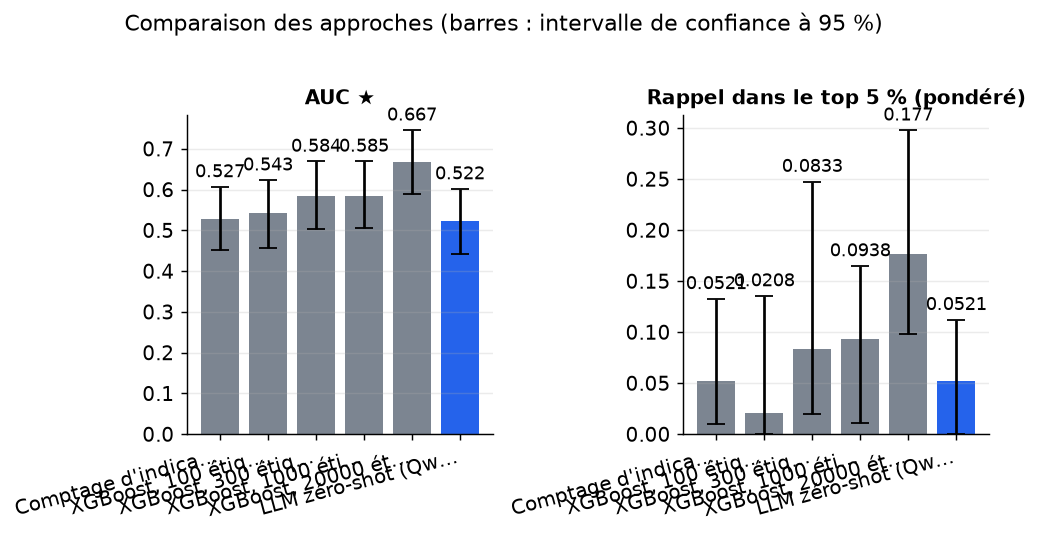

*Figure — Valeur de chaque métrique par approche (★ : métrique principale, à maximiser) ; les barres d'erreur donnent l'intervalle de confiance à 95 % sur 192 exemples de test.*

In [34]:
METRIC_LABELS = {"auc": "AUC", "auc_ci_low": "AUC, borne basse IC 95 %", "auc_ci_high": "AUC, borne haute IC 95 %",
                 "recall_at_top5pct": "Rappel dans le top 5 % (pondéré)", "n_labels": "Étiquettes d'entraînement",
                 "tokens_per_client": "Tokens par client", "latency_ms_per_client": "Latence par client (ms, médiane)"}
paired_note = {row["approche"]: f"différence appariée d'AUC vs LLM {row['AUC − AUC LLM']:+.3f} "
               f"[{row['IC bas']:+.3f} ; {row['IC haut']:+.3f}]" for row in paired_rows}
results = save_results({
    "primary_metric": "auc", "direction": "max", "metric_labels": METRIC_LABELS,
    "dataset": {**dataset_info, "n_examples": int(n_evaluated)},
    "approaches": [{"name": e["name"], "role": e["role"], "metrics": e["metrics"], "ci95": e["ci95"],
                    "latency_ms": e["latency_ms"],
                    "notes": e["notes"] + (" ; " + paired_note[e["name"]] if e["name"] in paired_note else "")}
                   for e in evaluated]})
display(results_table(results))
plot_comparison(results, metrics=["auc", "recall_at_top5pct"])

### Verdict sur l'hypothèse

Chaque critère est évalué automatiquement. Si l'intervalle d'AUC du LLM contient 0,5, il ne fait pas mieux que le **hasard** (prédicteur trivial) : tous les verdicts deviennent « non concluant », et c'est ce résultat qui doit être publié.

In [35]:
def verdict_table() -> pd.DataFrame:
    """Critères de l'hypothèse, évalués sur les chiffres de cette exécution."""
    eligible = best_llm["metrics"]["auc_ci_low"] > 0.5
    row = lambda name: paired_table.set_index("approche").loc[name] if name in set(paired_table["approche"]) else None
    count_row = row(count_run["name"])
    mid_budget = [r for r in paired_rows if r["étiquettes"] in (300, 1000)]
    full_xgb = max(xgboost_runs, key=lambda e: e["n_labels"])
    gap_full = full_xgb["metrics"]["auc"] - best_llm["metrics"]["auc"]
    checks = [
        ("LLM meilleur que le hasard (IC bas > 0,5)", eligible),
        ("LLM ≥ comptage + 0,03 d'AUC", best_llm["metrics"]["auc"] - count_run["metrics"]["auc"] >= 0.03),
        ("LLM non dépassé par XGBoost à 300-1 000 étiquettes", bool(mid_budget) and not any(r["dépasse le LLM"] for r in mid_budget)),
        ("XGBoost (toutes étiquettes) ≥ LLM + 0,05", gap_full >= 0.05)]
    return pd.DataFrame([{"critère": name, "verdict": ("oui" if ok else "non") if eligible or i == 0 else "non concluant"}
                         for i, (name, ok) in enumerate(checks)])


display(verdict_table())
print(f"LLM évalué : {best_llm['name']} | AUC {best_llm['metrics']['auc']:.3f} "
      f"[{best_llm['metrics']['auc_ci_low']:.3f} ; {best_llm['metrics']['auc_ci_high']:.3f}]")

,critère,verdict
0,"LLM meilleur que le hasard (IC bas > 0,5)",non
1,"LLM ≥ comptage + 0,03 d'AUC",non concluant
2,LLM non dépassé par XGBoost à 300-1 000 étique...,non concluant
3,"XGBoost (toutes étiquettes) ≥ LLM + 0,05",non concluant


LLM évalué : LLM zéro-shot (Qwen2.5-0.5B-Instruct) | AUC 0.522 [0.441 ; 0.601]


## 6. Analyse des résultats

### AUC selon le nombre d'étiquettes

La figure clé de l'expérience. La courbe XGBoost monte avec le budget d'étiquettes, et l'intervalle bootstrap est tracé en bande. Les LLM zéro-shot et le comptage, qui n'utilisent aucune étiquette, sont des **lignes horizontales**. Le point où la courbe croise la ligne du LLM indique combien d'étiquettes « vaut » le LLM.

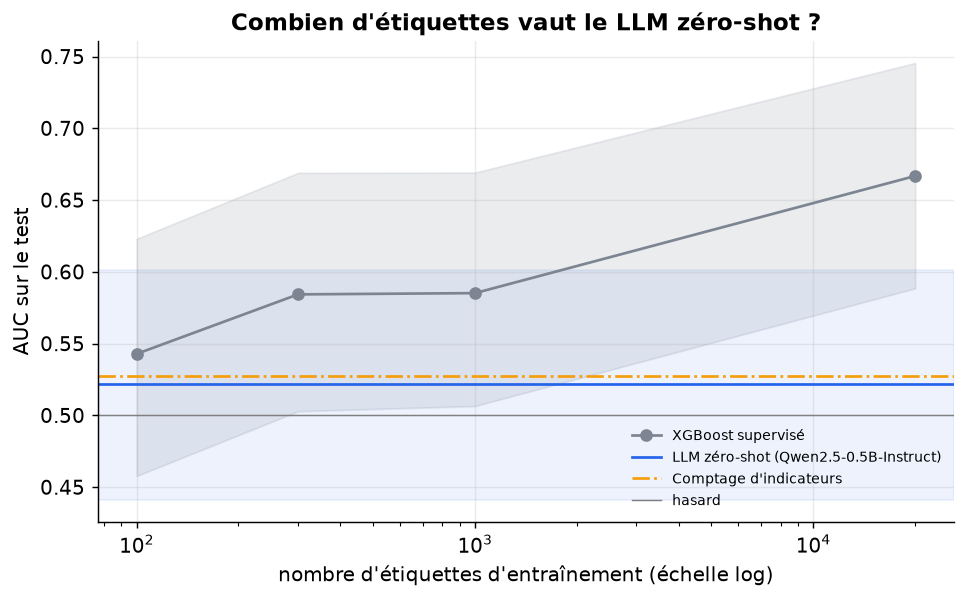

*Figure — AUC de XGBoost selon le nombre d'étiquettes (bande : IC 95 %), comparée aux approches sans étiquette (lignes horizontales). Le croisement donne le budget d'étiquettes équivalent.*

In [36]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
budgets = [e["n_labels"] for e in xgboost_runs]
ax.plot(budgets, [e["metrics"]["auc"] for e in xgboost_runs], marker="o", color=COLORS["reference"], label="XGBoost supervisé")
ax.fill_between(budgets, [e["metrics"]["auc_ci_low"] for e in xgboost_runs],
                [e["metrics"]["auc_ci_high"] for e in xgboost_runs], color=COLORS["reference"], alpha=0.15)
line_styles = ["-", "--", ":"]
for i, e in enumerate([e for e in evaluated if e["role"] == "new"]):
    ax.axhline(e["metrics"]["auc"], color=COLORS["new"], linestyle=line_styles[i % 3], label=e["name"])
    ax.axhspan(e["metrics"]["auc_ci_low"], e["metrics"]["auc_ci_high"], color=COLORS["new"], alpha=0.08)
ax.axhline(count_run["metrics"]["auc"], color=COLORS["accent"], linestyle="-.", label=count_run["name"])
ax.axhline(0.5, color="grey", linewidth=0.8, label="hasard")
ax.set_xscale("log")
ax.set_xlabel("nombre d'étiquettes d'entraînement (échelle log)")
ax.set_ylabel("AUC sur le test")
ax.set_title("Combien d'étiquettes vaut le LLM zéro-shot ?")
ax.legend(fontsize=8, loc="lower right")
save_figure(fig, "auc_vs_labels", "AUC de XGBoost selon le nombre d'étiquettes (bande : IC 95 %), comparée aux "
            "approches sans étiquette (lignes horizontales). Le croisement donne le budget d'étiquettes équivalent.")

### Le profil change-t-il le jugement à alerte égale ?

C'est l'argument central de la source : deux clients qui déclenchent **les mêmes alertes** doivent pouvoir recevoir des scores différents selon leur profil. Dans chaque groupe de clients ayant le même nombre d'alertes, on calcule l'AUC du LLM. Le comptage vaut 0,5 par construction dans un tel groupe et n'est donc pas affiché. Une AUC au-dessus de 0,5 montre que le LLM ajoute de l'information au simple comptage. La figure compare aussi la distribution des scores par classe.

,alertes déclenchées,défauts,sans défaut,AUC du LLM dans le groupe
0,0,38,45,0.457
1,1,39,31,0.533
2,2,14,16,0.647


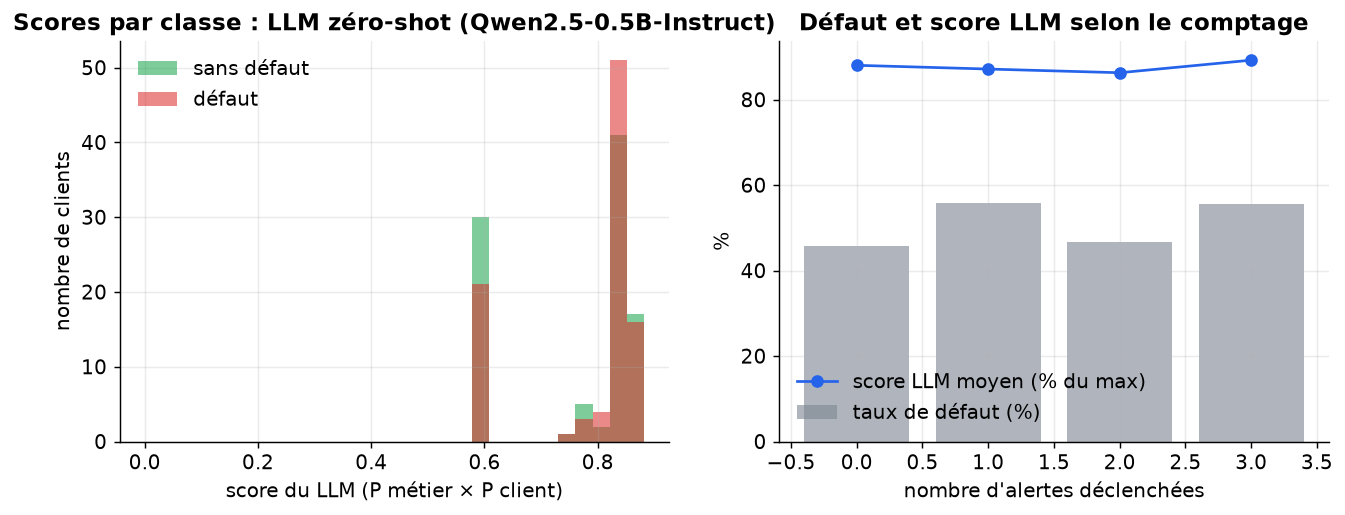

*Figure — Gauche : distribution des scores du LLM par classe (plus elles sont séparées, meilleure est l'AUC). Droite : taux de défaut du test équilibré et score moyen du LLM selon le nombre d'alertes.*

In [37]:
count_eval = count_run["matrix"][:, 0]
llm_eval = best_llm["matrix"][:, 0]
within_rows = []
for value in np.unique(count_eval):
    group = count_eval == value
    n_pos, n_neg = int(y_eval[group].sum()), int((1 - y_eval[group]).sum())
    if min(n_pos, n_neg) >= 10:  # assez de clients de chaque classe pour une AUC lisible
        within_rows.append({"alertes déclenchées": int(value), "défauts": n_pos, "sans défaut": n_neg,
                            "AUC du LLM dans le groupe": round(fast_auc(y_eval[group], llm_eval[group]), 3)})
display(pd.DataFrame(within_rows))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0, max(llm_eval.max(), 1e-6), 30)
for label, color, name in [(0, COLORS["good"], "sans défaut"), (1, COLORS["bad"], "défaut")]:
    axes[0].hist(llm_eval[y_eval == label], bins=bins, alpha=0.55, color=color, label=name)
axes[0].set_xlabel("score du LLM (P métier × P client)")
axes[0].set_ylabel("nombre de clients")
axes[0].set_title(f"Scores par classe : {best_llm['name']}")
axes[0].legend()
rates = pd.DataFrame({"alertes": count_eval, "score": llm_eval, "défaut": y_eval}).groupby("alertes")
axes[1].bar(rates.size().index, 100 * rates["défaut"].mean(), color=COLORS["reference"], alpha=0.6, label="taux de défaut (%)")
axes[1].plot(rates.size().index, 100 * rates["score"].mean() / max(llm_eval.max(), 1e-6), color=COLORS["new"],
             marker="o", label="score LLM moyen (% du max)")
axes[1].set_xlabel("nombre d'alertes déclenchées")
axes[1].set_ylabel("%")
axes[1].set_title("Défaut et score LLM selon le comptage")
axes[1].legend()
save_figure(fig, "scores_by_class", "Gauche : distribution des scores du LLM par classe (plus elles sont séparées, "
            "meilleure est l'AUC). Droite : taux de défaut du test équilibré et score moyen du LLM selon le nombre d'alertes.")

### Contrôle d'équité sommaire (phase publique)

Le genre n'est jamais fourni aux modèles, mais la question sur le métier peut en être un **indicateur indirect** (*proxy*). On compare l'AUC par genre sur le test : un écart net signale un traitement inégal à explorer. Ce n'est pas un audit d'équité complet. Les groupes trop petits (< 20 par classe) sont écartés.

In [38]:
if PHASE == "public" and "gender" in test.columns:
    gender = test["gender"].to_numpy()[:n_evaluated]
    fairness_rows = []
    for e in [count_run, next((x for x in xgboost_runs if x["n_labels"] == 1000), xgboost_runs[-1])] + \
             [x for x in evaluated if x["role"] == "new"]:
        row = {"approche": e["name"]}
        for group in sorted(set(gender)):
            mask = gender == group
            if min(int(y_eval[mask].sum()), int((1 - y_eval[mask]).sum())) >= 20:
                row[f"AUC {group}"] = round(float(np.nanmean([fast_auc(y_eval[mask], e["matrix"][mask, d])
                                                              for d in range(e["matrix"].shape[1])])), 3)
        fairness_rows.append(row)
    display(pd.DataFrame(fairness_rows))
else:
    print("Aucune variable d'audit disponible : contrôle d'équité non réalisé dans cette phase.")

,approche,AUC F,AUC M
0,Comptage d'indicateurs,0.544,0.510
1,"XGBoost, 1000 étiquettes",0.565,0.608
2,LLM zéro-shot (Qwen2.5-0.5B-Instruct),0.554,0.459


### Exemples d'erreurs (phase publique seulement)

Les **fausses alertes** les plus fortes (clients sans défaut que le LLM classe en tête) et les **défauts manqués** les plus nets (défauts classés en bas). Lire leurs profils aide à voir ce que le modèle sur-pondère, par exemple un métier ou un âge.

In [39]:
if PHASE == "public":
    view = test.iloc[:n_evaluated][["occupation", "age", "income", "credit_amount", "annuity",
                                    "employment_years"] + EXTRA_CATEGORICAL].copy()
    view["alertes"] = count_eval.astype(int)
    view["P métier"] = llm_runs[LLM_MODELS[0]]["scores"]["p_occupation"].to_numpy()[:n_evaluated]
    view["P client"] = llm_runs[LLM_MODELS[0]]["scores"]["p_client"].to_numpy()[:n_evaluated]
    view["score"], view["défaut"] = llm_eval, y_eval
    print("Fausses alertes les plus fortes :")
    display(view[view["défaut"] == 0].nlargest(5, "score").round(3))
    print("Défauts manqués les plus nets :")
    display(view[view["défaut"] == 1].nsmallest(5, "score").round(3))

Fausses alertes les plus fortes :


,occupation,age,income,credit_amount,annuity,employment_years,contract_type,income_type,education,alertes,P métier,P client,score,défaut
164,Realty agents,28.0,405000.0,270000.0,13500.0,2.064,Revolving loans,Commercial associate,Higher education,0,0.916,0.962,0.881,0
9,Accountants,34.0,180000.0,545040.0,25537.5,7.786,Cash loans,Commercial associate,Higher education,0,0.912,0.960,0.875,0
136,High skill tech staff,34.0,157500.0,900000.0,26446.5,4.257,Cash loans,Commercial associate,Secondary / secondary special,1,0.895,0.972,0.870,0
158,High skill tech staff,23.0,157500.0,180000.0,9000.0,3.316,Revolving loans,Working,Secondary / secondary special,1,0.895,0.972,0.870,0
1,Core staff,37.0,180000.0,1078200.0,34780.5,11.759,Cash loans,Working,Secondary / secondary special,1,0.889,0.970,0.863,0


Défauts manqués les plus nets :


,occupation,age,income,credit_amount,annuity,employment_years,contract_type,income_type,education,alertes,P métier,P client,score,défaut
72,Not reported,51.0,112500.0,269550.0,13909.5,NaN,Cash loans,Pensioner,Secondary / secondary special,0,0.618,0.958,0.592,1
69,Not reported,64.0,157500.0,583834.5,29938.5,NaN,Cash loans,Pensioner,Secondary / secondary special,0,0.618,0.960,0.593,1
118,Not reported,59.0,135000.0,544491.0,17694.0,NaN,Cash loans,Pensioner,Secondary / secondary special,0,0.618,0.961,0.594,1
166,Not reported,53.0,76500.0,180000.0,17532.0,NaN,Cash loans,Pensioner,Secondary / secondary special,1,0.618,0.961,0.594,1
137,Not reported,53.0,157500.0,601470.0,32760.0,NaN,Cash loans,Pensioner,Secondary / secondary special,0,0.618,0.963,0.595,1


### À retenir

- **Si** l'AUC du LLM zéro-shot dépasse celle du comptage de plus de 0,03, avec un intervalle au-dessus de 0,5, le jugement en contexte apporte quelque chose au-delà des seuils fixes. Le tableau « à alerte égale » dit si cet apport vient bien du profil.
- **Si** le point d'équivalence tombe vers 300 à 1 000 étiquettes, l'approche peut servir de **démarrage à froid**, quand on n'a pas encore d'historique. Au-delà, un modèle supervisé simple reprend l'avantage et doit être préféré.
- **Si** l'écart avec XGBoost entraîné sur toutes les étiquettes dépasse 0,05, le LLM reste un outil de tri provisoire, pas un remplaçant.
- À l'échelle réduite (modèle 0,5B, 200 clients), les intervalles sont larges et le modèle est bien plus faible que ceux de la source : un résultat proche du hasard est attendu et **ne réfute pas** la méthode. Seule l'échelle complète, et le contrôle positif, permettent de trancher.
- Quel que soit le chiffre, le métier peut servir d'indicateur indirect de groupes protégés. Un **test d'équité** complet est un préalable à tout usage, et le score ne doit servir qu'à trier des dossiers pour un analyste.

## 7. Bilan

> **Verdict** (confiance elevee). À l'échelle réduite (modèle de 0,5 milliard de paramètres sur CPU, 192 clients de test, un seul tirage d'étiquettes par budget), le LLM zéro-shot obtient une AUC de 0,522 [0,441 ; 0,601], au niveau du hasard et du comptage d'indicateurs (0,527). Le contrôle positif échoue : le modèle ne distingue pas un dossier très risqué d'un dossier sain. XGBoost entraîné sur 20 000 étiquettes est le seul à se distinguer (0,667, écart apparié de +0,145). Ces chiffres ne permettent pas de trancher sur l'approche, ni de la comparer aux résultats de la source obtenus avec un modèle bien plus capable. La comparaison est construite équitablement (mêmes clients, mêmes variables, seuils tirés du développement). Elle n'a simplement pas la puissance pour conclure.

*Échelle réduite seulement (192 exemples, CPU) : approches ou métriques différentes de celles de l'échelle réduite. Ces chiffres valident la mécanique ; ils sont indicatifs et à confirmer avec `SCALE = "full"`.*

| Approche | AUC ★ ↑ | AUC, borne basse IC 95 % ↑ | AUC, borne haute IC 95 % | Rappel dans le top 5 % (pondéré) ↑ | Étiquettes d'entraînement | Tokens par client ↓ | Latence par client (ms, médiane) ↓ | Latence médiane (ms) ↓ |
|---|---|---|---|---|---|---|---|---|
| Comptage d'indicateurs (référence) | 0,527 [0,452 ; 0,606] | 0,452 | 0,606 | 0,0521 [0,0103 ; 0,133] | 0 | — | **0,00717** | 0,01 |
| XGBoost, 100 étiquettes (référence) | 0,543 [0,458 ; 0,623] | 0,458 | 0,623 | 0,0208 [0 ; 0,135] | 100 | — | 0,0123 | 0,01 |
| XGBoost, 300 étiquettes (référence) | 0,584 [0,503 ; 0,669] | 0,503 | 0,669 | 0,0833 [0,0202 ; 0,248] | 300 | — | 0,0124 | 0,01 |
| XGBoost, 1000 étiquettes (référence) | 0,585 [0,507 ; 0,669] | 0,507 | 0,669 | 0,0938 [0,0114 ; 0,165] | 1e+03 | — | 0,0125 | 0,01 |
| XGBoost, 20000 étiquettes (référence) | **0,667 [0,589 ; 0,746]** | **0,589** | 0,746 | **0,177 [0,0982 ; 0,298]** | 2e+04 | — | 0,0124 | 0,01 |
| LLM zéro-shot (Qwen2.5-0.5B-Instruct) (nouvelle approche) | 0,522 [0,441 ; 0,601] | 0,441 | 0,601 | 0,0521 [0 ; 0,112] | 0 | 364 | 2,08e+03 | 2,08e+03 |

★ métrique principale · ↑ plus haut = meilleur · ↓ plus bas = meilleur · entre crochets : intervalle de confiance à 95 % (bootstrap) · en gras : la meilleure valeur.

**Réserves**

- Ce petit modèle répond presque toujours « oui », que le dossier soit sain ou très risqué. Son AUC proche du hasard ne dit rien sur ce que donnerait un modèle de décision plus gros.
- Avec 192 clients et un seul tirage par budget, on ne peut pas dire combien d'étiquettes « vaut » le LLM. Les écarts entre approches sont dans la marge d'erreur, sauf pour le modèle supervisé entraîné sur toutes les étiquettes.

**Limites**

- Le prêteur est d'Europe de l'Est et la date est probablement reconstituée : le découpage temporel peut ne pas refléter une vraie dérive dans le temps.
- Les six indicateurs ne viennent que de la table de demande ; aucun historique de remboursement ni de comportement n'est utilisé, ce qui plafonne toutes les approches.
- Les LLM ouverts de 3 Md de paramètres au plus sont bien plus petits que le modèle de la source : le résultat est un plancher de ce que l'approche peut donner.
- Le contrôle d'équité se limite à une AUC par genre ; le métier reste un proxy possible et un audit complet manque.
- À l'échelle réduite, 200 clients et un modèle 0,5B donnent des intervalles larges, qui ne permettent pas de trancher.

**Échelle réduite : ce qui diffère de l'échelle complète**

- À l'échelle réduite, Qwen2.5-0.5B-Instruct remplace les modèles 1,5B et 3B. Le test compte 200 clients (100 défauts) et le développement 20 000 demandes. Les budgets d'étiquettes s'arrêtent à 100, 300, 1 000 et « toutes », avec un seul tirage par budget. Le budget d'inférence est de 300 s, sur CPU en float32. La configuration et le tokeniseur des modèles 1,5B et 3B sont quand même vérifiés, sans leurs poids.

**Améliorations possibles**

- Le test est « plus récent » seulement au sens de la colonne de date du jeu. Il ne prouve pas que la méthode tient face à une vraie dérive dans le temps.
- Les latences (environ 2 s par client pour le LLM) valent pour ce processeur et ce petit modèle. Elles ne se transposent pas à un service de production.
- Ces AUC par sexe ne prouvent ni la présence ni l'absence de biais. Le test d'équité complet reste à faire avant tout usage.

**Et ensuite ?** Rejouer le même protocole sur vos données : `PHASE = "private"`, `SCALE = "full"`, après avoir préparé le jeu et la configuration décrits dans le README (section « Sur vos données »).